# Proyek Analisis Data: E-commerce public dataset
- **Nama:** Nova Rasyadina Anwar
- **Email:** novaml941@gmail.com
- **ID Dicoding:** novaml078i

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang memiliki jumlah pendapatan dari harga barang tanpa ongkos kirim tertinggi dan terendah pada pesanan delivered selama tahun 2017-2018, sebagai dasar penentuan prioritas stok dan anggaran promosi?
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata skor ulasan antara pesanan yang tiba tepat waktu dan yang tiba terlambat, serta pada keterlambatan berapa hari skor ulasan mulai menurun tajam, pada pesanan delivered selama tahun 2017-2018, sebagai dasar penentuan batas keterlambatan untuk peningkatan kinerja tim logistik?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load semua file dataset


In [2]:
customers_df = pd.read_csv('data/customers_dataset.csv')
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')
order_items_df = pd.read_csv('data/order_items_dataset.csv')
order_payments_df = pd.read_csv('data/order_payments_dataset.csv')
order_reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
orders_df = pd.read_csv('data/orders_dataset.csv')
product_category_df = pd.read_csv('data/product_category_name_translation.csv')
products_df = pd.read_csv('data/products_dataset.csv')
sellers_df = pd.read_csv('data/sellers_dataset.csv')

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:** (Opsional)
- Sebelumnya telah dibuat folder dengan nama"data" untuk menyimpan file dataset dan sembilan file dataser berhasil dimuat dalam dataframe pandas
- Tabel orders_df menjadi tabel transaksi utama yang berisikan order_id dan customer_id yang nantinyaaakan digabungkan dengan tabel lain pada tahap ekplorasi data.

### Assessing Data

#### Identifikasi Missing Value & Data Type

In [3]:
print("=== info orders_df ===")
orders_df.info()

print("\n=== missing values reviews ===")
print(order_reviews_df.isnull().sum())

print("\n=== missing values products ===")
print(products_df.isnull().sum())

print("\n=== pemeriksaan duplikasi pada data ===")
print("jumlah duplikasi pada customers_df:", customers_df.duplicated().sum())
print("jumlah duplikasi pada orders_df:", orders_df.duplicated().sum())

=== info orders_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

=== missing values reviews ===
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_an

#### Identifikasi masalah duplikasi pada ulasan, pesanan tanpa tanggal tiba, kategori tanpa terjemahan, serta periode atau tahun

In [4]:
print("order_id ganda pada order_reviews_df:", order_reviews_df.order_id.duplicated().sum())
print("Pesanan delivered tanpa tanggal tiba:",
      ((orders_df.order_status == "delivered") & orders_df.order_delivered_customer_date.isna()).sum())
print("Kategori tanpa terjemahan:",
      set(products_df.product_category_name.dropna()) - set(product_category_df.product_category_name))
print("Jumlah baris geolocation_df:", geolocation_df.shape[0])
print("Jumlah baris duplikat penuh pada geolocation_df:", geolocation_df.duplicated().sum())
print("Jumlah kode pos unik:", geolocation_df["geolocation_zip_code_prefix"].nunique())
print("\nJumlah pesanan per tahun:")
print(orders_df["order_purchase_timestamp"].str[:4].value_counts().sort_index())

order_id ganda pada order_reviews_df: 551
Pesanan delivered tanpa tanggal tiba: 8
Kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}
Jumlah baris geolocation_df: 1000163
Jumlah baris duplikat penuh pada geolocation_df: 261831
Jumlah kode pos unik: 19015

Jumlah pesanan per tahun:
order_purchase_timestamp
2016      329
2017    45101
2018    54011
Name: count, dtype: int64


**Steps to Take:**
- mengubah format lima kolom tanggal pada "oreders_df" dari tipe object menjadi format datetime
- mengisi nilai kosong pada variabel "product_category_name" di "products_df" dengan "unknown" kemudian menambahkan terjemahan manual terhadap dua kategori yang belum memiliki terjemahan, seperti pc_gamer dan portateis_cozinha_e_preparadores_de_alimentos
- meringkas order_reviews_df meenjadi saty baris untuk setiap order_id dengan menghitung rata-rata skor ulasan karena terdapat 551 order_id yang duplikat atau ganda
- meringkas geolocation_df menjadi satu baris untuk tiap kode pos setelah dilakukan penghapusan baris duplikat, karena satu kode pos memiliki banyak koordinat dan akan menduplikasikan baris saat digabungkan dengan customer_df
- delapan pesanan delivered tanpa tanggal tiba tidak dihapus dari data, tetapi ditandai pada kolom tanpa_tanggal_tiba. pesanan ini tetap digitung pada analisis pendapatan dan hanya dikeluarkan dari analisis keterlambatan dikarenakan selisih harinya tidak bisa dihitung

**Insight:** (Opsional)
- Kelima kolom pada "orders_df" masih terbaca sebagai tipe objek atau teks biasa. kolom in iperlu diubah ke format datetime agar selisih tanggal estimasi dan tanggal tiba dapat dihitung dalam hari dengan akurat
- terdapat 610 baris produk tanpa kategori pada products_df. baris ini tidak dihilangkan atau dibuang agar sampel analisis nya tidak berkurang, tetapi diisi dengan label unknown. selain itu juga dua kategori yaitu pc_gamer dan portateis_cozinha_e_preparadores_de_alimentos belum memiliki terjemahan bahasa inggris, sehingga akan diterjemahkan secara manual
- Kolom komentar ulasan yang kosong dibiarkan saja karena pembeli tidak wajib menulis komentar atau review saat memberi skor
- tidak ditemukan duplikasi data di "customers_df" maupun "orders_df" atau nilai duplikatnya adalah 0 yang berarti setiap barisnya mewakili entitas transaksi yang unik
- terdapat 551 order_id ganda pada order_reviews_df, sehingga ulasan perlu diringkas menjadi satu baris pesanan
- Terdapat delapan pesanan berstatus delivered tidak memiliki tanggal tiba. pesanan ini tetap  dipertahankan tetapi tidak dapat digunakan pada analisis keterlambatan
- tabel geolocation_df memiliki 1.000.163 baris, termasuk 261.831 baris duplikat, tetapi hanya memiliki 19.015 kode pos unik. yang berarti satu kode pos memiliki banyak koordinat, sehingga perlu untuk diringkas menjadi satu baris per kode pos
- pada proses accessing data di atas ditemukan bahwa pada tahun 2016 hanya terdapat 329 pesanan, sehingga akan sulit untuk dilakukan analsis karena data terlalu sedikit dan dapat mengalami bias, maka analisis ini difokuskan pada tahun 2017-2018 sesuai dengan pertanyaan bisnis yang telah dijabarkan sebelumnya.

### Cleaning Data

#### Fixing tipe data tanggal serta mengisi kategori kosong

In [5]:
date_columns= [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")

terjemahan_manual = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers"]
})
product_category_df = pd.concat([product_category_df, terjemahan_manual], ignore_index=True)

print("Kategori tanpa terjemahan:",
      set(products_df.product_category_name) - set(product_category_df.product_category_name) - {"unknown"})

orders_df.dtypes

Kategori tanpa terjemahan: set()


,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


#### Fixing duplikasi ulasan atau ulasan ganda

In [6]:
print("Jumlah baris ulasan sebelum diringkas:", order_reviews_df.shape[0])
order_reviews_df = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()
print("Jumlah baris ulasan sesudah diringkas:", order_reviews_df.shape[0])
print("Ulasan unik per pesanan:", order_reviews_df["order_id"].is_unique)

Jumlah baris ulasan sebelum diringkas: 99224
Jumlah baris ulasan sesudah diringkas: 98673
Ulasan unik per pesanan: True


#### fixing duplikasi pada geolocation

In [7]:
print("Jumlah baris geolocation_df sebelum:", geolocation_df.shape[0])
geolocation_df = geolocation_df.drop_duplicates()
print("Jumlah baris setelah menghapus duplikat:", geolocation_df.shape[0])

geolocation_df = geolocation_df.groupby("geolocation_zip_code_prefix", as_index=False).agg(
    lat=("geolocation_lat", "mean"),
    lng=("geolocation_lng", "mean")
)
print("Jumlah kode pos pada geolocation_df:", len(geolocation_df))
print("Kode pos ganda:", geolocation_df["geolocation_zip_code_prefix"].duplicated().sum())

Jumlah baris geolocation_df sebelum: 1000163
Jumlah baris setelah menghapus duplikat: 738332
Jumlah kode pos pada geolocation_df: 19015
Kode pos ganda: 0


#### Menandai pesanan delivered tanpa tanggal tiba

In [8]:
orders_df["tanpa_tanggal_tiba"] = (orders_df["order_status"] == "delivered") & orders_df["order_delivered_customer_date"].isna()
print("Pesanan delivered tanpa tanggal tiba:", orders_df["tanpa_tanggal_tiba"].sum())
print("Jumlah baris orders_df tetap:", orders_df.shape[0])

Pesanan delivered tanpa tanggal tiba: 8
Jumlah baris orders_df tetap: 99441


**Insight:** (Opsional)
- Lima kolom tanggal pada oredes_df  sudah bertipe datetine sehingga manipulasi tanggal lbisa dilakukan langsung tanpa harus konversi ulang
- Nilai kosong pada kategori produk diisi dengan "unknown" agar 610 produk tersebut tidak tersingkir dari analisis. dua kategori yang belum memiliki terjemahan sudah di tambahkan secara manual sehingga tidak ada lagi kategori yang tanpa terjemahan selain unknown
- order_reviews berhasil di ringkas menjadi satu baris per order_id, sehingga 551 order_id yang ganda tidak lagi menggandakan baris saat digabungkan
- Tabel geolocation pengalami penyusustan dari 1.000.163 baris menjadi 19.015 baris, satu baris per kode pos sehingga aman untuk digabungkan dengan tabel lain
- delapan pesanan delivered tanpa tanggal tiba ditandai pada kolom tanpa_tanggal_tiba dan tidak dihilangkan karena transaksinya tetap valid untuk analisis pendapatan.pesanan ini hanya dikeluarkan dari analisis keterlambatan pada tahap EDA nanti

### Menyimpan data untuk dashboard

In [9]:
payment_per_order = order_payments_df.groupby("order_id", as_index=False)["payment_value"].sum()

main_data = orders_df.merge(order_items_df, on="order_id", how="inner") \
                     .merge(products_df, on="product_id", how="left") \
                     .merge(product_category_df, on="product_category_name", how="left") \
                     .merge(customers_df, on="customer_id", how="left") \
                     .merge(payment_per_order, on="order_id", how="left") \
                     .merge(order_reviews_df, on="order_id", how="left") \
                     .merge(geolocation_df, left_on="customer_zip_code_prefix",
                            right_on="geolocation_zip_code_prefix", how="left")

main_data["category"] = main_data["product_category_name_english"].fillna(main_data["product_category_name"])

# lama keterlambatan: hari antara tanggal tiba dan tanggal estimasi (kosong jika belum tiba)
main_data["delay_days"] = (main_data["order_delivered_customer_date"] - main_data["order_estimated_delivery_date"]).dt.total_seconds() / (24*3600)

# hanya pesanan delivered pada tahun 2017-2018
main_data = main_data[(main_data["order_purchase_timestamp"].dt.year >= 2017) &
                      (main_data["order_purchase_timestamp"].dt.year <= 2018) &
                      (main_data["order_status"] == "delivered")]

main_data = main_data[["order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp",
                       "category", "price", "freight_value", "payment_value", "review_score",
                       "delay_days", "lat", "lng"]].copy()

print(main_data.shape)
main_data.head()

(109880, 12)


,order_id,customer_unique_id,customer_state,order_purchase_timestamp,category,price,freight_value,payment_value,review_score,delay_days,lat,lng
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,housewares,29.99,8.72,38.71,4.0,-7.107488,-23.577482,-46.587077
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,perfumery,118.70,22.76,141.46,4.0,-5.355729,-12.186877,-44.540232
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,2018-08-08 08:38:49,auto,159.90,19.22,179.12,5.0,-17.245498,-16.745150,-48.514783
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,RN,2017-11-18 19:28:06,pet_shop,45.00,27.20,72.20,5.0,-12.980069,-5.774002,-35.270976
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,SP,2018-02-13 21:18:39,stationery,19.90,8.72,28.62,5.0,-9.238171,-23.676257,-46.514580


In [10]:
print(main_data.shape)                                                  # (109880, 12)
print(main_data["order_id"].nunique())                                  # 96211
print(main_data.dropna(subset=["delay_days"])["order_id"].nunique())    # 96203
print(round(main_data["price"].sum(), 2))                               # 13181027.13
print(main_data.isnull().sum())

(109880, 12)
96211
96203
13181027.13
order_id                      0
customer_unique_id            0
customer_state                0
order_purchase_timestamp      0
category                      0
price                         0
freight_value                 0
payment_value                 0
review_score                823
delay_days                    8
lat                         288
lng                         288
dtype: int64


In [11]:
import os
os.makedirs("dashboard", exist_ok=True)

main_out = main_data.copy()
main_out[["payment_value", "review_score"]] = main_out[["payment_value", "review_score"]].round(2)
main_out[["lat", "lng"]] = main_out[["lat", "lng"]].round(4)
main_out["delay_days"] = main_out["delay_days"].round(6)
main_out.to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv tersimpan", main_out.shape)

main_data.csv tersimpan (109880, 12)


## Exploratory Data Analysis (EDA)

### Explore struktur dan sebaran data

#### Ringkasan statistik harga, pembayaran, serta produk

In [12]:
print("harga dan ongkos kirim per item")
print(order_items_df[["price", "freight_value"]].describe().round(2))

print("\n pembayaran")
print(order_payments_df[["payment_installments", "payment_value"]].describe().round(2))

print("\n berat dan jumlah foto produk")
print(products_df[["product_weight_g", "product_photos_qty"]].describe().round(1))

harga dan ongkos kirim per item
           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68

 pembayaran
       payment_installments  payment_value
count             103886.00      103886.00
mean                   2.85         154.10
std                    2.69         217.49
min                    0.00           0.00
25%                    1.00          56.79
50%                    1.00         100.00
75%                    4.00         171.84
max                   24.00       13664.08

 berat dan jumlah foto produk
       product_weight_g  product_photos_qty
count           32949.0             32341.0
mean             2276.5                 2.2
std              4282.0                 1.7
min                 0.0                 1.0
25%               300.0      

#### status pesanan, metode pembayaran, skor review atau ulasan, serta wilayah customer

In [13]:
print("=== status pesanan (%) ===")
print((orders_df["order_status"].value_counts(normalize=True) * 100).round(2))

print("\n=== metode pembayaran (%) ===")
print((order_payments_df["payment_type"].value_counts(normalize=True) * 100).round(1))

print("\n=== skor ulasan (%) ===")
print((order_reviews_df["review_score"].round().value_counts(normalize=True).sort_index() * 100).round(1))

print("\n=== pelanggan terbanyak per negara bagian ===")
print(customers_df["customer_state"].value_counts().head(5))
print("Jumlah negara bagian:", customers_df["customer_state"].nunique())
print("Jumlah customer_id:", customers_df["customer_id"].nunique(),
      "| Jumlah customer_unique_id:", customers_df["customer_unique_id"].nunique())

=== status pesanan (%) ===
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

=== metode pembayaran (%) ===
payment_type
credit_card    73.9
boleto         19.0
voucher         5.6
debit_card      1.5
not_defined     0.0
Name: proportion, dtype: float64

=== skor ulasan (%) ===
review_score
1.0    11.5
2.0     3.2
3.0     8.2
4.0    19.4
5.0    57.7
Name: proportion, dtype: float64

=== pelanggan terbanyak per negara bagian ===
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
Name: count, dtype: int64
Jumlah negara bagian: 27
Jumlah customer_id: 99441 | Jumlah customer_unique_id: 96096


#### Frekuensi jumlah cicilan

In [14]:
print("jumlah cicilan yang paling sering digunakan (jumlah transaksi)")
print(order_payments_df["payment_installments"].value_counts().head(5))

print("\njumlah cicilan yang paling sering digunakan (%)")
print((order_payments_df["payment_installments"].value_counts(normalize=True).head(5) * 100).round(2))

jumlah cicilan yang paling sering digunakan (jumlah transaksi)
payment_installments
1     52546
2     12413
3     10461
4      7098
10     5328
Name: count, dtype: int64

jumlah cicilan yang paling sering digunakan (%)
payment_installments
1     50.58
2     11.95
3     10.07
4      6.83
10     5.13
Name: proportion, dtype: float64


#### Jumlah pesanan setiap tahun dan bulan

In [15]:
print("=== jumlah pesanan per tahun ===")
print(orders_df.groupby(orders_df["order_purchase_timestamp"].dt.year).size())

pesanan_bulanan = orders_df[orders_df["order_status"] == "delivered"] \
    .groupby(orders_df["order_purchase_timestamp"].dt.to_period("M")).size()
print("\nBulan dengan pesanan delivered terbanyak:", pesanan_bulanan.idxmax(), "-", pesanan_bulanan.max(), "pesanan")

=== jumlah pesanan per tahun ===
order_purchase_timestamp
2016      329
2017    45101
2018    54011
dtype: int64

Bulan dengan pesanan delivered terbanyak: 2017-11 - 7289 pesanan


**Insight:** (Opsional)
- Harga item condong ke kanan yang rata-rata BRL nya 120.65, median BRL nya 74.99, dan maksimal nya BRL 6.735, kemudian rata-rata ongkos kirim nya BRL 19.99
- Besaran pembayaran setiap transaksi rata-rata BRL 154,10 dengan median BRL 100. Berdasarkan tabel frekuensi, jumlah cicilan yang paling sering digunakan adalah 1 kali, yaitu sebanyak 52.546 transaksi dengan persentase 50,58%. Jumlah cicilan maksimum adalah 24 kali.
- sebanyak 97.02% pesanan dengan status delivered. pesanan dibatalkan seebsar 0.63% dan tidak tersedia seebsar 0.61% sangat sedikit, sehingga pendapatan dan keterlambatan dianalisis dari pesanan yang delivered.
- sebanyak 73.9% pembayaran menggunakan kartu kredit, disusul oleh boleto sebesar 19.0% dan voucher sebesar 5.6%
- skor ulasan cenderung positif. sebanyak 57.7% bernilai 5 dan 11.5% bernilai 1
- pada tahun 2016 hanya terdapat 329 pesanan, kemudian 45.101 pada tahun 2017 dan 54.011 pada 2018. hal ini menjadi alasan analisis hanya dilakukan pada periode 2017-2018. bulan dengan pesaanan delivered terbanyak adalah november tahun 2017, yaitu sebesar 7.289 pesanan
- terdapat sebanyak 99.441 costumer_id tetapi hanya sejumlah 96.096 costumer_unique_id, yang berarti satu orang dapat memiliki beberapa customer_id. Itulah mengapa analisis RFM menggunakan customer_unique_id
- pelanggan tersebar di 27 negara bagian. SP sejumlah 41.746, RJ 12.852, dan MG 11.635 paling banyak
- berat poduk minimum yaang tidak wajar tercatat yaitu 0 gram. kolom berat tidak digunakan dalam analisis yang dilakukan sehingga tidak dibersihan


### Penggabungan Tabel

#### Penggabungan pesanan atau order, item, produk, dan terjemahan kategori

In [16]:
master_df = orders_df.merge(order_items_df, on="order_id", how="inner") \
                     .merge(products_df, on="product_id", how="left") \
                     .merge(product_category_df, on="product_category_name", how="left")

master_df["product_category_name_english"] = master_df["product_category_name_english"].fillna(master_df["product_category_name"])

master_df["year"] = master_df["order_purchase_timestamp"].dt.year
master_df["month"] = master_df["order_purchase_timestamp"].dt.month

print("Jumlah baris master_df:", len(master_df))
print("Jumlah nilai kategori:", master_df["product_category_name_english"].nunique())
print("Item dengan kategori unknown:", (master_df["product_category_name_english"] == "unknown").sum())
print("Pesanan unik:", master_df["order_id"].nunique(),
      "| Penjual unik:", master_df["seller_id"].nunique(),
      "| Produk unik:", master_df["product_id"].nunique())

print("\n=== jumlah item per pesanan (%) ===")
print((order_items_df.groupby("order_id").size().value_counts(normalize=True).sort_index().head(4) * 100).round(1))

Jumlah baris master_df: 112650
Jumlah nilai kategori: 74
Item dengan kategori unknown: 1603
Pesanan unik: 98666 | Penjual unik: 3095 | Produk unik: 32951

=== jumlah item per pesanan (%) ===
1    90.1
2     7.6
3     1.3
4     0.5
Name: proportion, dtype: float64


**Insight:** (Opsional)
- gasil gabungan ytabel berisi 112.650 baris item dari sebanyak 98.666 pesanan, 3.095 penjual, dan 32.951 produk
- sebanyak 90.1% pesanan yang hanya berisi 1 item, sehinggatidak jauh berbeda antara jumlah baris item dan jumlah pesanannya.
- terdapat 74 nilai kategori termasuk pula unknown, dan 1.603 baris item dengan kategori unknown

### Ekplore Pertanyaan 1: Kategori produk apa saja yang memiliki jumlah pendapatan dari harga barang tanpa ongkos kirim tertinggi dan terendah pada pesanan delivered selama tahun 2017-2018, sebagai dasar penentuan prioritas stok dan anggaran promosi?


#### Pendapatan serta kontribusi setiap kategori produk

In [17]:
# pendapatan hanya dari pesanan delivered pada tahun 2017-2018
master_filtered = master_df[(master_df["year"] >= 2017) & (master_df["year"] <= 2018) &
                            (master_df["order_status"] == "delivered")]

category_revenue = master_filtered.groupby("product_category_name_english").agg(
    total_revenue=("price", "sum"),
    total_orders=("order_id", "nunique"),
    total_items=("order_item_id", "count"),
    avg_price=("price", "mean")
).reset_index().rename(columns={"product_category_name_english": "category"})

category_revenue["contribution_pct"] = category_revenue["total_revenue"] / category_revenue["total_revenue"].sum() * 100
category_revenue = category_revenue.sort_values("total_revenue", ascending=False).reset_index(drop=True)
category_revenue["cumulative_pct"] = category_revenue["contribution_pct"].cumsum()

print("Jumlah kategori terbaca:", len(category_revenue))
print("Total pendapatan 2017-2018 (BRL):", f"{category_revenue['total_revenue'].sum():,.2f}")
print("Kontribusi 5 kategori teratas:", f"{category_revenue['contribution_pct'].head(5).sum():.2f}%")
print("Kontribusi 10 kategori teratas:", f"{category_revenue['contribution_pct'].head(10).sum():.2f}%")
print("Jumlah kategori untuk mencapai 80% pendapatan:", (category_revenue['cumulative_pct'] <= 80).sum() + 1)

Jumlah kategori terbaca: 74
Total pendapatan 2017-2018 (BRL): 13,181,027.13
Kontribusi 5 kategori teratas: 39.88%
Kontribusi 10 kategori teratas: 62.47%
Jumlah kategori untuk mencapai 80% pendapatan: 18


#### top sepuluh kategori dengan pendapatan terbesar

In [18]:
category_revenue.head(10)

,category,total_revenue,total_orders,total_items,avg_price,contribution_pct,cumulative_pct
0,health_beauty,1229557.50,8610,9422,130.498567,9.328237,9.328237
1,watches_gifts,1163465.91,5491,5855,198.713221,8.826823,18.155060
2,bed_bath_table,1022955.77,9267,10945,93.463296,7.760820,25.915880
3,sports_leisure,952840.40,7513,8414,113.244640,7.228878,33.144758
4,computers_accessories,888055.59,6518,7632,116.359485,6.737378,39.882136
5,furniture_decor,706237.17,6258,8095,87.243628,5.357983,45.240119
6,housewares,614341.62,5734,6783,90.570783,4.660802,49.900921
7,cool_stuff,609158.00,3552,3711,164.149286,4.621476,54.522397
8,auto,577838.39,3802,4132,139.844722,4.383865,58.906262
9,garden_tools,469135.40,3443,4263,110.048182,3.559172,62.465434


#### Delapan kategori dengan pendapatan terkecil

In [19]:
category_revenue.tail(8)

,category,total_revenue,total_orders,total_items,avg_price,contribution_pct,cumulative_pct
66,arts_and_craftmanship,1814.01,23,24,75.583750,0.013762,99.953900
67,diapers_and_hygiene,1365.89,24,36,37.941389,0.010363,99.964263
68,pc_gamer,1306.95,7,8,163.368750,0.009915,99.974178
69,flowers,1110.04,29,33,33.637576,0.008421,99.982600
70,home_comfort_2,760.27,24,30,25.342333,0.005768,99.988368
71,cds_dvds_musicals,730.00,12,14,52.142857,0.005538,99.993906
72,fashion_childrens_clothes,519.95,7,7,74.278571,0.003945,99.997851
73,security_and_services,283.29,2,2,141.645000,0.002149,100.000000


#### Pertumbuhan pendapatan kategori tertinggi

In [20]:
# data 2018 hanya tersedia sampai Agustus, sehingga dibandingkan pada bulan yang sama (Jan-Agu)
growth_df = master_filtered[master_filtered["month"] <= 8].pivot_table(
    index="product_category_name_english", columns="year", values="price", aggfunc="sum"
).fillna(0)
growth_df["growth_pct"] = (growth_df[2018] / growth_df[2017] - 1) * 100

growth_top10 = growth_df.loc[category_revenue["category"].head(10)].reset_index() \
    .rename(columns={"product_category_name_english": "category"})
growth_top10

year,category,2017,2018,growth_pct
0,health_beauty,243521.70,755724.50,210.331482
1,watches_gifts,201137.86,687855.20,241.981962
2,bed_bath_table,254444.82,532358.85,109.223693
3,sports_leisure,216724.33,517166.26,138.628612
4,computers_accessories,214631.27,496269.30,131.219477
5,furniture_decor,170858.58,381649.57,123.371615
6,housewares,127534.54,391823.46,207.229289
7,cool_stuff,206306.37,227743.70,10.391017
8,auto,125247.48,343288.30,174.087990
9,garden_tools,138051.15,212186.20,53.701146


**Insight:** (Opsional)
- setelah dilakukan pembatasan pada pesanan delivered selama periode 2017 hingga 2018, terdapat 74 kategori dengan total pendapatan sekitar 13.18 juta. pendapatan dihitung dari haga barang tanpa ongkos kirim
- lima teratas menyumbangkan sekitar 39.9% dari total pendapatan serta sepuluh kategori teratas sekitar 62.5%. dari 74 kategori terdapat 18 yang sudah cukup untuk mencapai 80% pendapatan
- dari sisi pendapatan dipimpin oleh health_beuty, sedangkan dari sisi jumlah pesanan dipimpin oleh bed_bath_table. perbedaannya terdapat pada harga rata-rata yaitu watches_gifts sekitar BRL 199, jauh di atas bed_bath_table sekitar BRL 93
- kategori bawah seperti security_and_services sejumlah dua pesanan dan fashion _childerns_chlotes sejumlah tujuh pesanan hampir tidak memberikan kontribusi
- delapan dari sepuluh kategori atas tumbuh lebih dari 100% dari tahun 2017 ke 2018 pada bulan januari sampai agustus. pertumbuhan tercepat terdapat pada watches_gifts yaitu sekitar 242%, health_beauty sebesar 210%, serta housewares sebesar 207%. cool_stuff hanya tumbuh sekitar 10% dan garden_tools sekitar 54%

### Eksplore Pertanyaan 2: Bagaimana perbedaan rata-rata skor ulasan antara pesanan yang tiba tepat waktu dan yang tiba terlambat, serta pada keterlambatan berapa hari skor ulasan mulai menurun tajam, pada pesanan delivered selama tahun 2017-2018, sebagai dasar penentuan batas keterlambatan untuk peningkatan kinerja tim logistik?

#### Lamanya pengiriman dan keterlambatan pesanan

In [21]:
delivered_df = orders_df[(orders_df["order_status"] == "delivered") &
                         (orders_df["order_purchase_timestamp"].dt.year >= 2017) &
                         (orders_df["order_purchase_timestamp"].dt.year <= 2018)].copy()

print("Pesanan delivered 2017-2018:", len(delivered_df))
print("Pesanan tanpa tanggal tiba (dikeluarkan dari analisis keterlambatan):", delivered_df["order_delivered_customer_date"].isnull().sum())

delivered_df = delivered_df.dropna(subset=["order_delivered_customer_date"])

delivered_df["delivery_days"] = (delivered_df["order_delivered_customer_date"] - delivered_df["order_purchase_timestamp"]).dt.total_seconds() / (24*3600)
delivered_df["estimate_days"] = (delivered_df["order_estimated_delivery_date"] - delivered_df["order_purchase_timestamp"]).dt.total_seconds() / (24*3600)
# delay_days > 0 berarti barang tiba setelah tanggal estimasi
delivered_df["delay_days"] = (delivered_df["order_delivered_customer_date"] - delivered_df["order_estimated_delivery_date"]).dt.total_seconds() / (24*3600)
delivered_df["is_late"] = delivered_df["delay_days"] > 0

print("Jumlah pesanan dianalisis:", len(delivered_df))
print("Persentase keterlambatan:", f"{delivered_df['is_late'].mean() * 100:.2f}%")

delivered_df[["delivery_days", "estimate_days", "delay_days"]].describe().round(2)

Pesanan delivered 2017-2018: 96211
Pesanan tanpa tanggal tiba (dikeluarkan dari analisis keterlambatan): 8
Jumlah pesanan dianalisis: 96203
Persentase keterlambatan: 8.13%


,delivery_days,estimate_days,delay_days
count,96203.00,96203.00,96203.00
mean,12.54,23.65,-11.11
std,9.53,8.60,10.09
min,0.53,2.01,-146.02
25%,6.76,18.32,-16.22
50%,10.21,23.22,-11.82
75%,15.68,28.37,-6.38
max,209.63,155.14,188.98


#### Perbandingan skor ulasan pesanan

In [22]:
review_delay_df = delivered_df.merge(order_reviews_df, on="order_id")
review_delay_df["is_negative"] = review_delay_df["review_score"] <= 2

print("Jumlah pesanan yang memiliki ulasan:", len(review_delay_df))

ringkasan = review_delay_df.groupby("is_late").agg(
    jumlah_pesanan=("order_id", "count"),
    rata_rata_skor=("review_score", "mean"),
    median_skor=("review_score", "median"),
    persen_ulasan_buruk=("is_negative", lambda x: x.mean() * 100)
).round(2)
print(ringkasan)

selisih = ringkasan.loc[False, "rata_rata_skor"] - ringkasan.loc[True, "rata_rata_skor"]
print(f"\nSelisih rata-rata skor (tepat waktu - terlambat): {selisih:.2f} poin")

Jumlah pesanan yang memiliki ulasan: 95560
         jumlah_pesanan  rata_rata_skor  median_skor  persen_ulasan_buruk
is_late                                                                  
False             87902            4.30          5.0                 9.17
True               7658            2.57          2.0                53.98

Selisih rata-rata skor (tepat waktu - terlambat): 1.73 poin


#### Korelasi keterlambatan dengan skor ulasan

In [23]:
print("Korelasi Spearman (seluruh pesanan)  :", round(review_delay_df[["delay_days", "review_score"]].corr(method="spearman").iloc[0, 1], 3))
terlambat_saja = review_delay_df[review_delay_df["is_late"]]
print("Korelasi Spearman (pesanan terlambat):", round(terlambat_saja[["delay_days", "review_score"]].corr(method="spearman").iloc[0, 1], 3))

Korelasi Spearman (seluruh pesanan)  : -0.177
Korelasi Spearman (pesanan terlambat): -0.521


#### Pengelompokan dari lamanya keterlambatan

In [24]:
bins = [-np.inf, -7, 0, 3, 7, 14, np.inf]
labels = ["Lebih awal >7 hari", "Lebih awal 0-7 hari", "Telat 0-3 hari", "Telat 3-7 hari", "Telat 7-14 hari", "Telat >14 hari"]
review_delay_df["delay_group"] = pd.cut(review_delay_df["delay_days"], bins=bins, labels=labels)

delay_group_df = review_delay_df.groupby("delay_group", observed=True).agg(
    jumlah_pesanan=("order_id", "count"),
    rata_rata_skor=("review_score", "mean"),
    persen_ulasan_buruk=("is_negative", lambda x: x.mean() * 100)
).round(2).reset_index()
delay_group_df

,delay_group,jumlah_pesanan,rata_rata_skor,persen_ulasan_buruk
0,Lebih awal >7 hari,70673,4.32,8.92
1,Lebih awal 0-7 hari,17229,4.20,10.19
2,Telat 0-3 hari,2635,3.77,19.09
3,Telat 3-7 hari,1773,2.32,61.25
4,Telat 7-14 hari,1748,1.75,78.03
5,Telat >14 hari,1502,1.71,78.63


**Insight:** (Opsional)
- pada pesanan terkirim tahun 2017 hingga 2018, rata-rata lamanya pengiriman 12,5 hari (median 10,2), estimasi rata-ratanya yaitu 23,7 hari. median delay_days bernilai -11,8, yang berarti pesanan tiba jauh lebih awal dari estimasi pada sebagian besarnya.
- nilai ekstrem berada di kedua ujung, yaitu 146 hari (paling awal) dan 189 hari(paling lambat) sebelum atau sesudah estimasi. nilai ini tidak dihapus karena merupakan data engiriman yang tercatat
- Sebanyak 8,13% pesanan tiba setelah tanggal estimasi dari 96.203 pesanan yang memiliki tanggal tiba
- rata-rata skor pesanan yang tepat waktu adalah 4,30, sedangkan pesanan yang terlambat adalah 2,57, selisih nya sekitar 1,73 poin dari rentang 1 sampai 5. ulasan buruk dengan skor 1 atau 2 hanya 9,2% pada pesanan tepat waktu, tetapi 54,0% di pesanan terlambat.
- korelasi spearman pada seluruh pesanan adalah -0,18. sebagian besar pesanan tidak terlambat yang menyebabkkan angka ini kecil. pada pesanan terlambat korelasinya adalah -0,52 yang berarti semakin lama terlambat maka semakin rendah skornya
- Keterlambatan sekecil 0-3 hari sudah berkaitan dengan penurunan skor. rata-rata skor kelompok telat 0-3 hari adalah 3,77. turun 0,43 poin dari kelompok yang lebih awal 0-7 hari (4,20). penurunan tersebut lebih besar dibanding selisih antara dua kelompok yang tibanya lebih awal, yaitu sebesar 0,12 poin (4,32 menjadi 4,20). persentase ulasan buruk atau negatif juga naik dari 10,19% menjadi 19,09% atau hampir dua kali lipat
- penurunan paling tajam terjadi pada keterlambatan 3-7 hari, dengan skor 2,32 dan ulasan buruk sebesar 61,25%. setelah lebih dari seminggu, skor bertahan di 1,71 sampai 1,75

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang memiliki jumlah pendapatan dari harga barang tanpa ongkos kirim tertinggi dan terendah pada pesanan delivered selama tahun 2017-2018, sebagai dasar penentuan prioritas stok dan anggaran promosi?


#### Top lima kategori dengan pendapatan terbesar dan terkecil

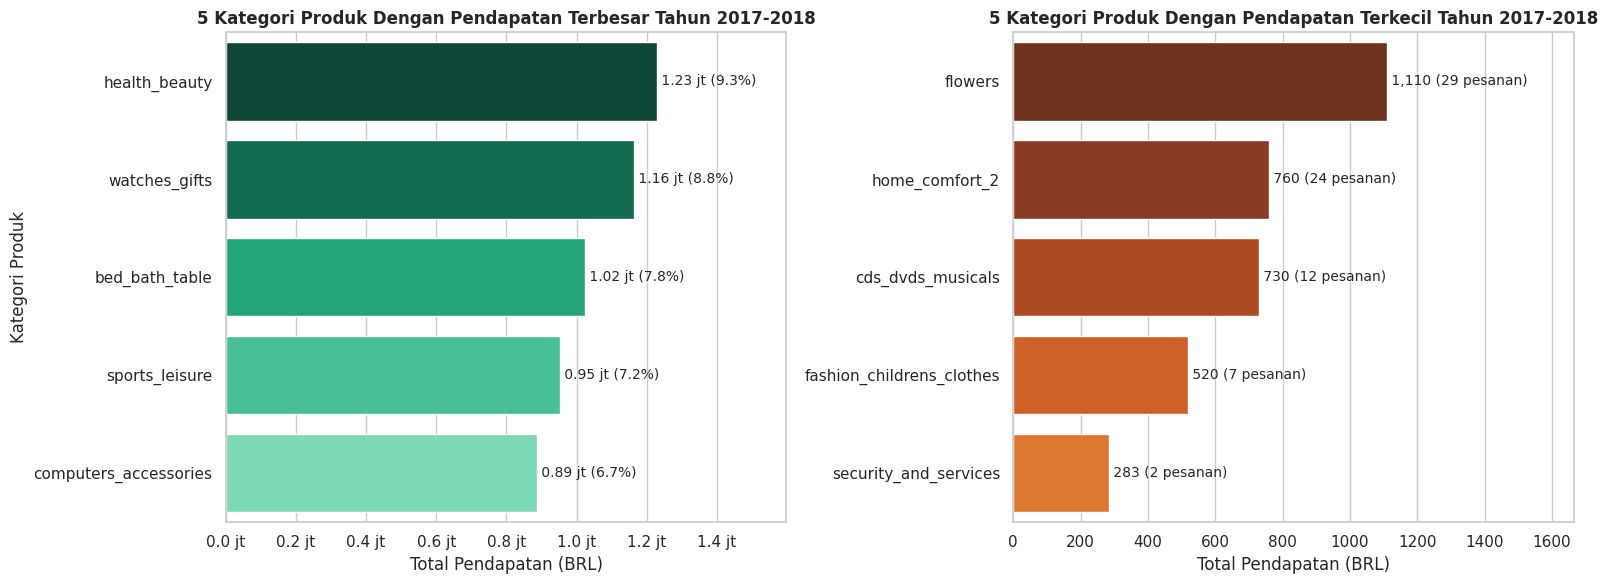

In [25]:
category_revenue_sorted = category_revenue.sort_values(by="total_revenue", ascending=False)
top5 = category_revenue_sorted.head(5)
bottom5 = category_revenue_sorted.tail(5).sort_values("total_revenue", ascending=False)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

sns.barplot(
    x="total_revenue", y="category", hue="category", data=top5,
    palette=["#064e3b", "#047857", "#10b981", "#34d399", "#6ee7b7"],
    legend=False, ax=ax[0]
)
ax[0].set_title("5 Kategori Produk Dengan Pendapatan Terbesar Tahun 2017-2018", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Total Pendapatan (BRL)")
ax[0].set_ylabel("Kategori Produk")
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f} jt"))
for i, (rev, pct) in enumerate(zip(top5["total_revenue"], top5["contribution_pct"])):
    ax[0].text(rev, i, f" {rev/1e6:.2f} jt ({pct:.1f}%)", va="center", fontsize=10)
ax[0].set_xlim(0, top5["total_revenue"].max() * 1.3)

sns.barplot(
    x="total_revenue", y="category", hue="category", data=bottom5,
    palette=["#7c2d12", "#9a3412", "#c2410c", "#ea580c", "#f97316"],
    legend=False, ax=ax[1]
)
ax[1].set_title("5 Kategori Produk Dengan Pendapatan Terkecil Tahun 2017-2018", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Total Pendapatan (BRL)")
ax[1].set_ylabel("")
for i, (rev, n) in enumerate(zip(bottom5["total_revenue"], bottom5["total_orders"])):
    ax[1].text(rev, i, f" {rev:,.0f} ({n} pesanan)", va="center", fontsize=10)
ax[1].set_xlim(0, bottom5["total_revenue"].max() * 1.5)

plt.tight_layout()
plt.show()

#### Pemusatan pendapatan atau kurva pareto

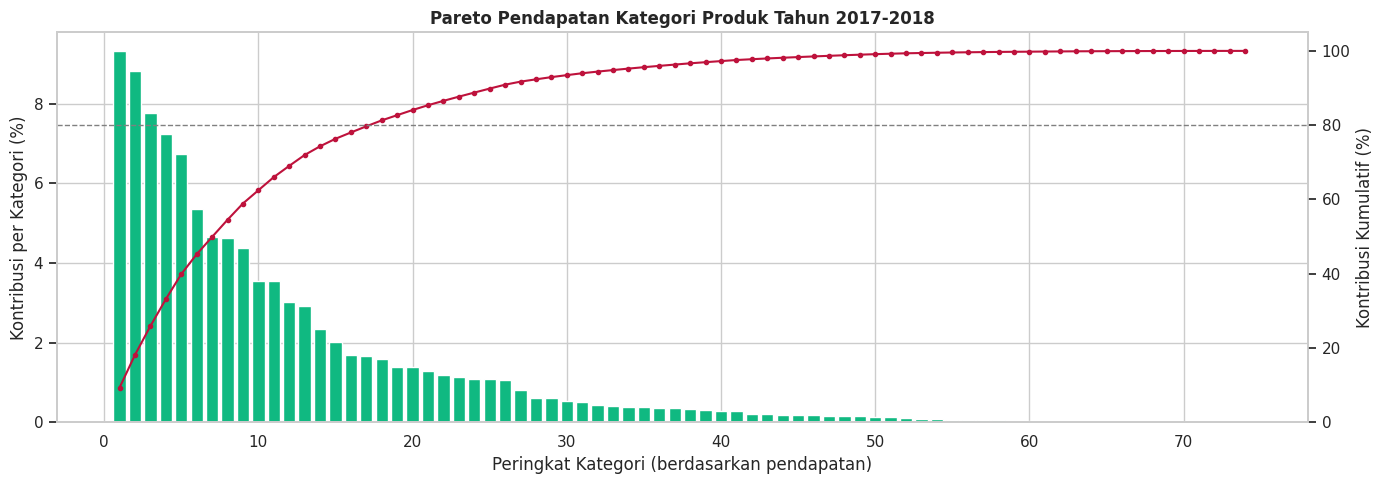

In [26]:
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(1, len(category_revenue_sorted) + 1)
ax.bar(x, category_revenue_sorted["contribution_pct"], color="#10b981")
ax.set_xlabel("Peringkat Kategori (berdasarkan pendapatan)")
ax.set_ylabel("Kontribusi per Kategori (%)")
ax2 = ax.twinx()
ax2.plot(x, category_revenue_sorted["cumulative_pct"], color="#be123c", marker="o", markersize=3)
ax2.axhline(80, color="gray", linestyle="--", linewidth=1)
ax2.set_ylabel("Kontribusi Kumulatif (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)
ax.set_title("Pareto Pendapatan Kategori Produk Tahun 2017-2018", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

#### Pertumbuhan pendapatan dari sepuluh kategori teratas

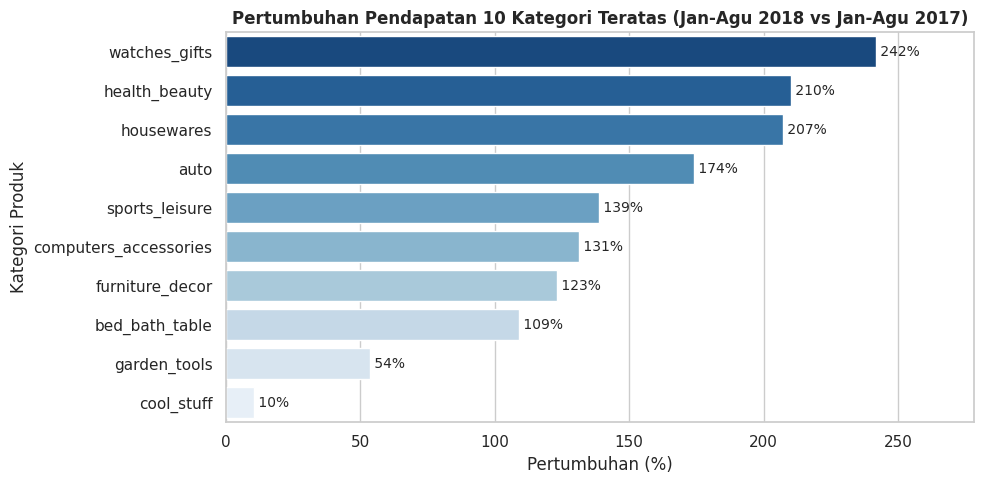

In [27]:
growth_plot = growth_top10.sort_values("growth_pct", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x="growth_pct", y="category", hue="category", data=growth_plot,
            palette="Blues_r", legend=False)
plt.title("Pertumbuhan Pendapatan 10 Kategori Teratas (Jan-Agu 2018 vs Jan-Agu 2017)", fontsize=12, fontweight="bold")
plt.xlabel("Pertumbuhan (%)")
plt.ylabel("Kategori Produk")
for i, v in enumerate(growth_plot["growth_pct"]):
    plt.text(v, i, f" {v:.0f}%", va="center", fontsize=10)
plt.xlim(0, growth_plot["growth_pct"].max() * 1.15)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- lima kategor teratas mengalai penurunan yag lanbat, mulai dari health_beauty dengan nilai RBL 1,23 juta hingga computers_acessories dengan nilai BRL 0,89 juta. selisih hatga antara keduanya hanya sekitar BRL 0,34 juta, sehingga persaingan di urutan atas masih cukup sengit.
- jarak ke kategori terbawah sangat jauh. pendapatan lima kategori dengan penghasilan terendah hanya mencapai antara BRL 283 hingga BRL 1.110, yang jauh lebih kecil sekali dibandingkan dengan kategori tertinggi
- kurva pareto atau konsentrasi meningkat tajam di awal dan memotong garis 80% pada kategori ke 18. sisanya, 56 kategori, membentuk ekor yang panjang dengan kontribusi yang kecil.
- delapan batang melewati 100% pada grafik pertumbuhan. cool_stuff dan garden_tools tampak lebih pendek dibandingkan dengan yang lain, sehingga keduanya tertinggal dari pertumbuhan platform secara keseluruhan

### Pertanyaan 2: Bagaimana perbedaan rata-rata skor ulasan antara pesanan yang tiba tepat waktu dan yang tiba terlambat, serta pada keterlambatan berapa hari skor ulasan mulai menurun tajam, pada pesanan delivered selama tahun 2017-2018, sebagai dasar penentuan batas keterlambatan untuk peningkatan kinerja tim logistik?

#### rata-rata skor ulasan terhadap pesanan yang tepat waktu dan terlambat

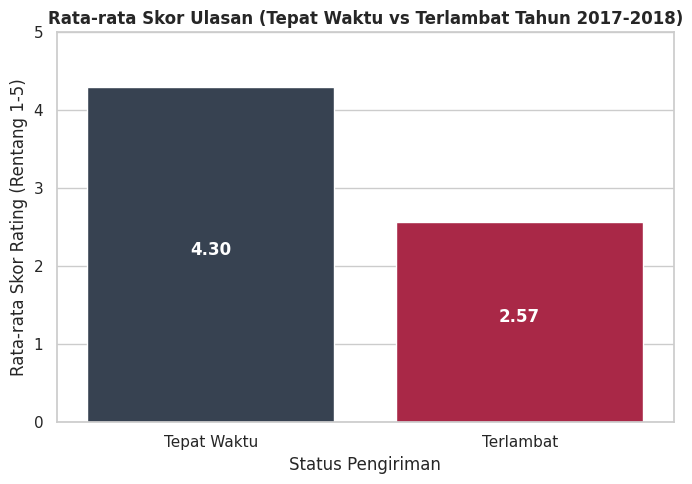

In [28]:
review_avg = review_delay_df.groupby("is_late")["review_score"].mean().reset_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x="is_late", y="review_score", hue="is_late", data=review_avg,
    palette=["#334155", "#be123c"], legend=False, dodge=False
)
plt.xticks(ticks=[0, 1], labels=["Tepat Waktu", "Terlambat"])
plt.title("Rata-rata Skor Ulasan (Tepat Waktu vs Terlambat Tahun 2017-2018)", fontsize=12, fontweight="bold")
plt.xlabel("Status Pengiriman")
plt.ylabel("Rata-rata Skor Rating (Rentang 1-5)")
plt.ylim(0, 5)

for index, row in review_avg.iterrows():
    plt.text(index, row.review_score / 2, f"{row.review_score:.2f}", color="white", ha="center", fontweight="bold", fontsize=12)

plt.tight_layout()
plt.show()

#### Distribusi skor ulasan berdasarkan status pengiriman

Persentase skor ulasan per status pengiriman (%):
review_score     1    2     3     4     5
Tepat Waktu    6.5  2.7   8.0  20.4  62.4
Terlambat     46.1  8.0  11.3  12.4  22.2


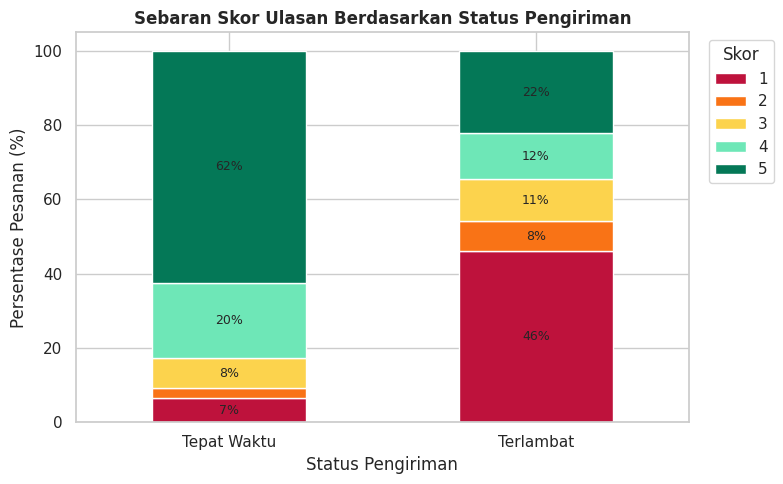

In [29]:
dist_df = pd.crosstab(review_delay_df["is_late"], review_delay_df["review_score"].round().astype(int), normalize="index") * 100
dist_df.index = ["Tepat Waktu", "Terlambat"]
print("Persentase skor ulasan per status pengiriman (%):")
print(dist_df.round(1))

ax = dist_df.plot(kind="bar", stacked=True, figsize=(8, 5),
                  color=["#be123c", "#f97316", "#fcd34d", "#6ee7b7", "#047857"])
ax.set_title("Sebaran Skor Ulasan Berdasarkan Status Pengiriman", fontsize=12, fontweight="bold")
ax.set_xlabel("Status Pengiriman")
ax.set_ylabel("Persentase Pesanan (%)")
ax.set_xticklabels(dist_df.index, rotation=0)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0f}%" if v >= 5 else "" for v in container.datavalues],
                 label_type="center", fontsize=9)
ax.legend(title="Skor", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### Skor ulasan dan ulasan buruk berdasarkan kelompok keterlambatan

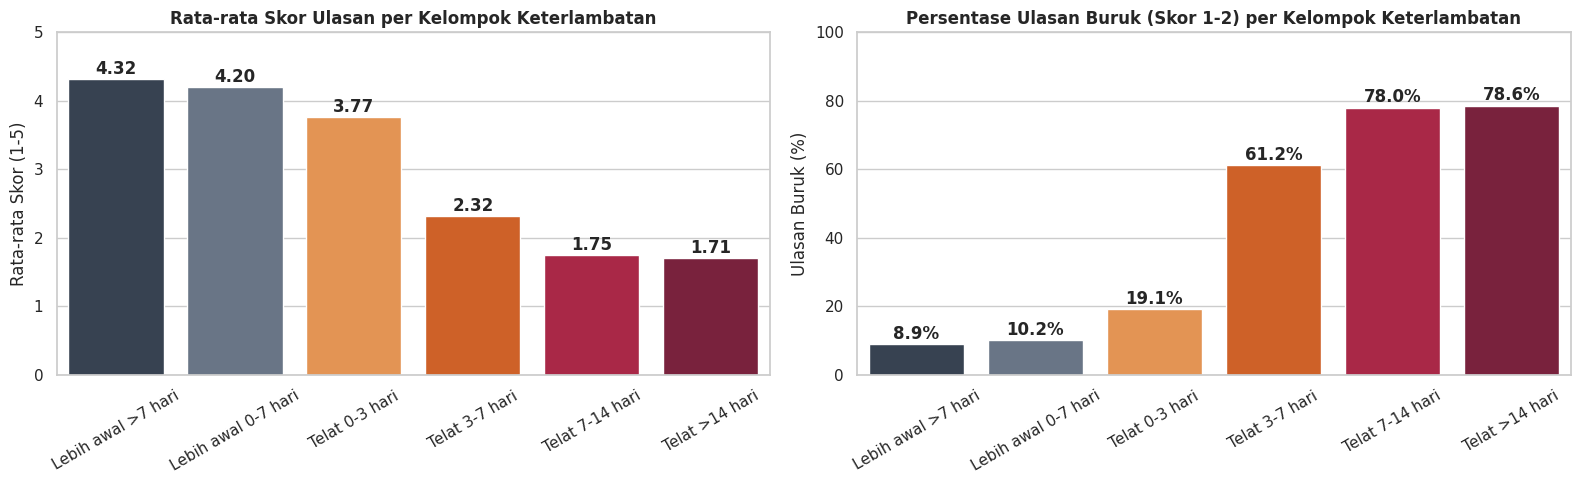

In [30]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))
warna = ["#334155", "#64748b", "#fb923c", "#ea580c", "#be123c", "#881337"]

sns.barplot(x="delay_group", y="rata_rata_skor", hue="delay_group", data=delay_group_df,
            palette=warna, legend=False, dodge=False, ax=ax[0])
ax[0].set_title("Rata-rata Skor Ulasan per Kelompok Keterlambatan", fontsize=12, fontweight="bold")
ax[0].set_xlabel("")
ax[0].set_ylabel("Rata-rata Skor (1-5)")
ax[0].set_ylim(0, 5)
ax[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(delay_group_df["rata_rata_skor"]):
    ax[0].text(i, v + 0.07, f"{v:.2f}", ha="center", fontweight="bold")

sns.barplot(x="delay_group", y="persen_ulasan_buruk", hue="delay_group", data=delay_group_df,
            palette=warna, legend=False, dodge=False, ax=ax[1])
ax[1].set_title("Persentase Ulasan Buruk (Skor 1-2) per Kelompok Keterlambatan", fontsize=12, fontweight="bold")
ax[1].set_xlabel("")
ax[1].set_ylabel("Ulasan Buruk (%)")
ax[1].set_ylim(0, 100)
ax[1].tick_params(axis="x", rotation=30)
for i, v in enumerate(delay_group_df["persen_ulasan_buruk"]):
    ax[1].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Rata-rata sskor pesanan yang terlambat adalah 2.57, sekitar 40% lebih rendah dibanding pesanan tepat waktu dengan skor 4,30, atau selisih 1.73 poin
- pada grafik sebaran, skor 5 mencapai sekitar 62% pada pesanan pada pesanan yang tepat waktu. pada pesanan terlambat, skor 1 paling dominan yaitu sekitar 46%, sedangkan skor 5 hanya sekitar 22%. pelanggan yang menerima barang dengan terlambat cenderung memberi penilaian yang lebih rendah
- pada grafik per kelompok, waktu keterlambatan 0-3 hari sudah menurunkan skor menjadi 3.77, atau turun 0.43 poin dari kelompok yang lebih awal 0-7 hari (4.20). penurunan ini lebih besar dibandingkan selisih antar dua kelompok yang tiba lebih awal, yaitu sebesar 0.12 poin (4.32 menjadi 4.20). skor turun lebih lanjut menjadi 2.32 di keterlambatan 3-7 hari, kemudian berada di sekitar 1.7 pada keterlambatan lebih dari 7 hari
- Persentase ulasan buruk naik hampir dua kali lipat, dari 10.19% (lebih awal 0-7 hari) menjadi 19.09% (telat 0-3 hari), kemudian melonjak menjadi 61.25% pada keterlambatan 3-7 hari dan mencapai 78.03% (telat 7-14 hari) serta 78.63% (telat lebih dari 14 hari). Lonjakan terbesar terjadi pada kelompok telat 3-7 hari, sehingga titik kritisnya berada di sekitar hari ketiga. Angka pada grafik dibulatkan satu desimal, sedangkan angka pada insight mengikuti tabel.
- Pesanan yang datang lebih cepat tidak menurunkan skor. Kelompok yang datang lebih awal lebih dari 7 hari memiliki skor 4.32, sedikit lebih tinggi dibandingkan dengan kelompok yang datang lebih awal 0 sampai 7 hari, yaitu 4.20

## Analisis Lanjutan (Opsional)

- **RFM Analysis** bertujuan mengelompokkan pelanggan berdasarkan waktu pembelian terakhir (recency), jumlah transaksi (frequency), dan total nilai transaksi (monetary), sebagai dasar guna menentukan pelanggan yang perlu dipertahankan atau diaktifkan kembali.
- **Manual grouping** bertujuan membagi pelanggan ke dalam segmen berdasarkan aturan bisnis dari skor recency, frequency, dan monetary, tanpa algoritma machine learning.
- **Geospatial analysis** bertujuan melihat sebaran lokasi pelanggan dan wilayah dengan persentase keterlambatan tinggi, sebagai dasar perbaikan kinerja layanan pengiriman di wilayah tertentu.

#### Menghitung recency, frequency, dan monetary setiap pelanggan

In [31]:
payment_per_order = order_payments_df.groupby("order_id", as_index=False)["payment_value"].sum()

rfm_base = orders_df[(orders_df["order_status"] == "delivered") &
                     (orders_df["order_purchase_timestamp"].dt.year >= 2017) &
                     (orders_df["order_purchase_timestamp"].dt.year <= 2018)]

recent_date = rfm_base["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = rfm_base.merge(payment_per_order, on="order_id") \
                 .merge(customers_df, on="customer_id")

rfm = rfm_df.groupby("customer_unique_id").agg({
    "order_purchase_timestamp": lambda x: (recent_date - x.max()).days,
    "order_id": "nunique",
    "payment_value": "sum"
}).reset_index()

rfm.columns = ["customer_unique_id", "Recency", "Frequency", "Monetary"]

print("Jumlah pelanggan unik:", len(rfm))
print("Tanggal acuan recency:", recent_date.date())
print("\nPersentase pelanggan berdasarkan frekuensi belanja:")
print((rfm["Frequency"].value_counts(normalize=True).sort_index() * 100).round(2))
rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)

Jumlah pelanggan unik: 93104
Tanggal acuan recency: 2018-08-30

Persentase pelanggan berdasarkan frekuensi belanja:
Frequency
1     97.00
2      2.75
3      0.19
4      0.03
5      0.01
6      0.01
7      0.00
9      0.00
15     0.00
Name: proportion, dtype: float64


,Recency,Frequency,Monetary
count,93104.00,93104.00,93104.00
mean,236.70,1.03,165.15
std,150.94,0.21,226.38
min,1.00,1.00,9.59
25%,114.00,1.00,63.04
50%,218.00,1.00,107.78
75%,345.00,1.00,182.50
max,602.00,15.00,13664.08


### top lima pelanggan urutan teratas pada setiap ukuran RFM

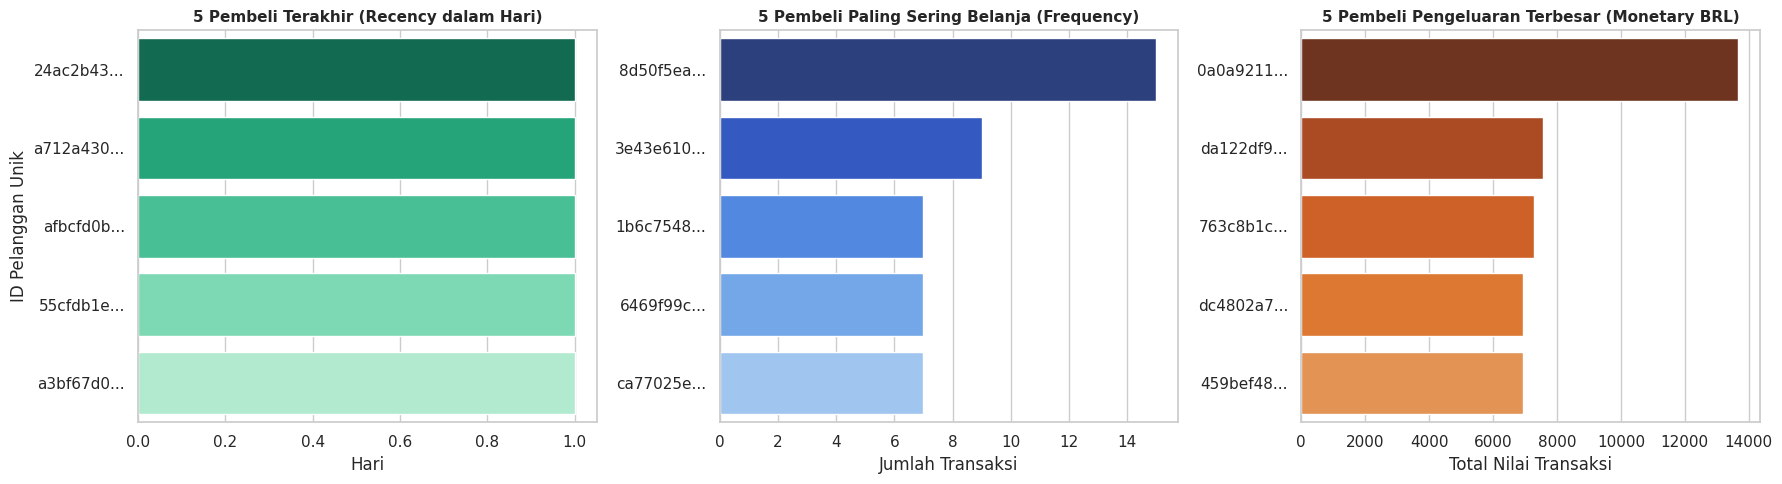

In [32]:
def potong_id(data):
    return [i[:8] + "..." for i in data["customer_unique_id"]]

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

d0 = rfm.sort_values(by="Recency", ascending=True).head(5)
sns.barplot(x="Recency", y="customer_unique_id", hue="customer_unique_id", data=d0,
            palette=["#047857", "#10b981", "#34d399", "#6ee7b7", "#a7f3d0"], legend=False, ax=ax[0])
ax[0].set_title("5 Pembeli Terakhir (Recency dalam Hari)", fontsize=11, fontweight='bold')
ax[0].set_xlabel("Hari")
ax[0].set_ylabel("ID Pelanggan Unik")
ax[0].set_yticks(range(5)); ax[0].set_yticklabels(potong_id(d0))

d1 = rfm.sort_values(by="Frequency", ascending=False).head(5)
sns.barplot(x="Frequency", y="customer_unique_id", hue="customer_unique_id", data=d1,
            palette=["#1e3a8a", "#1d4ed8", "#3b82f6", "#60a5fa", "#93c5fd"], legend=False, ax=ax[1])
ax[1].set_title("5 Pembeli Paling Sering Belanja (Frequency)", fontsize=11, fontweight="bold")
ax[1].set_xlabel("Jumlah Transaksi")
ax[1].set_ylabel("")
ax[1].set_yticks(range(5)); ax[1].set_yticklabels(potong_id(d1))

d2 = rfm.sort_values(by="Monetary", ascending=False).head(5)
sns.barplot(x="Monetary", y="customer_unique_id", hue="customer_unique_id", data=d2,
            palette=["#7c2d12", "#c2410c", "#ea580c", "#f97316", "#fb923c"], legend=False, ax=ax[2])
ax[2].set_title("5 Pembeli Pengeluaran Terbesar (Monetary BRL)", fontsize=11, fontweight="bold")
ax[2].set_xlabel("Total Nilai Transaksi")
ax[2].set_ylabel("")
ax[2].set_yticks(range(5)); ax[2].set_yticklabels(potong_id(d2))

plt.tight_layout()
plt.show()

### Nilai top lima pelanggan teratas pada setiap ukuran RFM

In [33]:
print("5 pembeli dengan recency terbaik")
print(rfm.sort_values("Recency", ascending=True).head(5)[["customer_unique_id", "Recency"]])
print("\n5 pembeli paling sering belanja")
print(rfm.sort_values("Frequency", ascending=False).head(5)[["customer_unique_id", "Frequency"]])
print("\n5 pembeli dengan pengeluaran terbesar")
print(rfm.sort_values("Monetary", ascending=False).head(5)[["customer_unique_id", "Monetary"]])

5 pembeli dengan recency terbaik
                     customer_unique_id  Recency
13395  24ac2b4327e25baf39f2119e4228976a        1
60876  a712a430955027da5bc257a10073a390        1
64045  afbcfd0b9c5233e7ccc73428526fbb52        1
31279  55cfdb1ec3c5bf60d9ccc0d5f276f8a9        1
59591  a3bf67d0b92528d2fe5c379dd905bf66        1

5 pembeli paling sering belanja
                     customer_unique_id  Frequency
51290  8d50f5eadf50201ccdcedfb9e2ac8455         15
22711  3e43e6105506432c953e165fb2acf44c          9
10035  1b6c7548a2a1f9037c1fd3ddfed95f33          7
36602  6469f99c1f9dfae7733b25662e7f1782          7
73727  ca77025e7201e3b30c44b472ff346268          7

5 pembeli dengan pengeluaran terbesar
                     customer_unique_id  Monetary
3716   0a0a92112bd4c708ca5fde585afaa872  13664.08
79420  da122df9eeddfedc1dc1f5349a1a690c   7571.63
43051  763c8b1c9c68a0229c42c9fc6f662b93   7274.88
80246  dc4802a71eae9be1dd28f5d788ceb526   6929.31
25360  459bef486812aa25204be022145caa62   692

**Insight:**
- Pembeli dengan recency terbaik terakhir membeli 1 hari sebelum tanggal acuan (30 Agustus 2018), jauh lebih baru dibandingkan rata-rata recency seluruh pelanggan yang mencapai 236,70 hari.
- Frekuensi belanja tertinggi mencapai 15 transaksi, jauh di atas rata-rata 1,03 transaksi. Pembeli seperti ini hanya segelintir, karena 97% pelanggan hanya berbelanja satu kali.
- Pengeluaran terbesar mencapai BRL 13.664,08, sekitar 83 kali rata-rata pengeluaran pelanggan (BRL 165,15). Lima pembeli teratas pada setiap ukuran merupakan pengecualian, sehingga tidak mewakili perilaku mayoritas pelanggan.

### Segmentasi pelanggan menggunakan manual grouping

In [34]:
rfm["r_score"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["f_score"] = rfm["Frequency"].clip(upper=3)
rfm["m_score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

def tentukan_segmen(row):
    if row["f_score"] >= 2 and row["r_score"] >= 3:
        return "Pelanggan Loyal Aktif"
    if row["f_score"] >= 2:
        return "Pelanggan Loyal Pasif"
    if row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Baru Bernilai Tinggi"
    if row["r_score"] >= 3:
        return "Baru Bernilai Rendah"
    if row["m_score"] >= 3:
        return "Lama Bernilai Tinggi"
    return "Lama Bernilai Rendah"

rfm["segment"] = rfm.apply(tentukan_segmen, axis=1)

segment_df = rfm.groupby("segment").agg(
    jumlah_pelanggan=("customer_unique_id", "count"),
    rata_recency=("Recency", "mean"),
    rata_frequency=("Frequency", "mean"),
    rata_monetary=("Monetary", "mean"),
    total_monetary=("Monetary", "sum")
).round(2).sort_values("total_monetary", ascending=False).reset_index()
segment_df["persen_pelanggan"] = (segment_df["jumlah_pelanggan"] / segment_df["jumlah_pelanggan"].sum() * 100).round(2)
segment_df["persen_pendapatan"] = (segment_df["total_monetary"] / segment_df["total_monetary"].sum() * 100).round(2)
segment_df

,segment,jumlah_pelanggan,rata_recency,rata_frequency,rata_monetary,total_monetary,persen_pelanggan,persen_pendapatan
0,Baru Bernilai Tinggi,22432,111.43,1.00,261.18,5858882.36,24.09,38.10
1,Lama Bernilai Tinggi,21665,362.06,1.00,264.24,5724754.12,23.27,37.23
2,Lama Bernilai Rendah,23620,362.47,1.00,63.83,1507687.66,25.37,9.81
3,Baru Bernilai Rendah,22598,111.53,1.00,63.01,1423796.74,24.27,9.26
4,Pelanggan Loyal Aktif,1534,112.18,2.14,315.05,483293.03,1.65,3.14
5,Pelanggan Loyal Pasif,1255,350.90,2.08,300.77,377461.53,1.35,2.45


### Jumlah pelanggan dan kontribusi nilai transaksi per segmen.

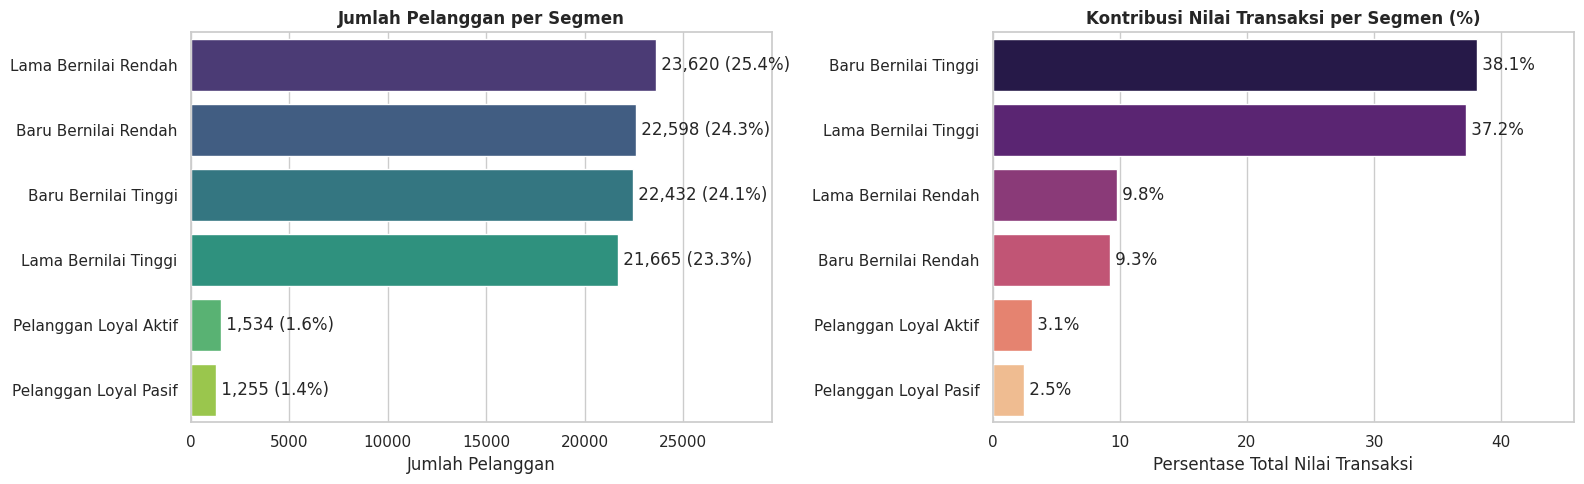

In [35]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

urut = segment_df.sort_values("jumlah_pelanggan", ascending=False)
sns.barplot(x="jumlah_pelanggan", y="segment", hue="segment", data=urut, palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Jumlah Pelanggan per Segmen", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Jumlah Pelanggan")
ax[0].set_ylabel("")
for i, (n, p) in enumerate(zip(urut["jumlah_pelanggan"], urut["persen_pelanggan"])):
    ax[0].text(n, i, f" {n:,} ({p:.1f}%)", va="center")
ax[0].set_xlim(0, urut["jumlah_pelanggan"].max() * 1.25)

urut2 = segment_df.sort_values("total_monetary", ascending=False)
sns.barplot(x="persen_pendapatan", y="segment", hue="segment", data=urut2, palette="magma", legend=False, ax=ax[1])
ax[1].set_title("Kontribusi Nilai Transaksi per Segmen (%)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Persentase Total Nilai Transaksi")
ax[1].set_ylabel("")
for i, p in enumerate(urut2["persen_pendapatan"]):
    ax[1].text(p, i, f" {p:.1f}%", va="center")
ax[1].set_xlim(0, urut2["persen_pendapatan"].max() * 1.2)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- 97% pelanggan hanya membelanjakan sekali dalam periode ini. Pelanggan yang membeli lebih dari satu kali hanya sekitar 3%.
- Pelanggan yang setia, baik yang aktif maupun pasif, mencapai sekitar 3% dari total jumlah pelanggan, namun hanya memberikan kontribusi sekitar 5,6% dari seluruh nilai penjualan. Mereka biasanya belanja sekitar BRL 300 hingga 315, hampir dua kali lipat dari rata-rata belanja seluruh pelanggan yang hanya BRL 165.
- Segmen lama dengan nilai tinggi memiliki 21.665 pelanggan (23,3%) yang memiliki rata-rata nilai transaksi BRL 264 dan berkontribusi sebesar 37,2% dari total nilai transaksi. Pelanggan dalam segmen ini terakhir membeli secara rata-rata 362 hari sebelum hari acuan, sehingga menjadi kesempatan terbesar untuk program mengaktifkan kembali pelanggan.
- Segmen baru yang memiliki nilai tinggi (24,1% pelanggan, 38,1% nilai transaksi) perlu ditingkatkan agar mereka kembali berbelanja sebelum menjadi pelanggan tetap.
- Dua segmen yang memiliki nilai tinggi, yaitu segmen baru dan segmen lama, mencakup sekitar 47% dari total pelanggan tetapi menghasilkan sekitar 75% dari total nilai transaksi. Segmen dengan nilai rendah mencakup sekitar 50% pelanggan, namun mereka hanya berkontribusi sekitar 19%.

### Menggabungkan Pesanan dengan Pelanggan serta Koordinat

In [36]:
geo_orders = delivered_df.merge(customers_df, on="customer_id") \
                         .merge(payment_per_order, on="order_id", how="left") \
                         .merge(order_reviews_df, on="order_id", how="left") \
                         .merge(geolocation_df, left_on="customer_zip_code_prefix",
                                right_on="geolocation_zip_code_prefix", how="left")

print("Jumlah pesanan:", geo_orders["order_id"].nunique())
print("Pesanan tanpa koordinat:", geo_orders["lat"].isnull().sum())

Jumlah pesanan: 96203
Pesanan tanpa koordinat: 264


### Ringkasan per negara bagian

In [37]:
state_df = geo_orders.groupby("customer_state").agg(
    jumlah_pelanggan=("customer_unique_id", "nunique"),
    jumlah_pesanan=("order_id", "nunique"),
    total_pendapatan=("payment_value", "sum"),
    rata_skor=("review_score", "mean"),
    persen_terlambat=("is_late", lambda x: x.mean() * 100),
    lat=("lat", "mean"),
    lng=("lng", "mean")
).round(2).reset_index().sort_values("jumlah_pesanan", ascending=False)

state_df["persen_pesanan"] = (state_df["jumlah_pesanan"] / state_df["jumlah_pesanan"].sum() * 100).round(2)
state_df.head(10)

,customer_state,jumlah_pelanggan,jumlah_pesanan,total_pendapatan,rata_skor,persen_terlambat,lat,lng,persen_pesanan
25,SP,39058,40399,5755521.34,4.25,5.90,-23.17,-47.05,41.99
18,RJ,11879,12310,2046698.14,3.97,13.52,-22.75,-43.17,12.80
10,MG,10969,11319,1814317.79,4.19,5.63,-19.92,-44.44,11.77
22,RS,5150,5327,858710.29,4.19,7.17,-29.71,-51.95,5.54
17,PR,4750,4903,779319.58,4.24,5.02,-24.79,-50.79,5.10
23,SC,3441,3537,592707.68,4.13,9.78,-27.24,-49.56,3.68
4,BA,3155,3253,590949.59,3.93,14.05,-13.02,-39.46,3.38
6,DF,2013,2074,344946.06,4.14,7.09,-15.81,-47.98,2.16
7,ES,1925,1992,316690.84,4.08,12.25,-20.15,-40.49,2.07
8,GO,1889,1950,333238.10,4.10,8.21,-16.61,-49.34,2.03


### Peta sebaran pelanggan dan keterlambatan per negara bagian

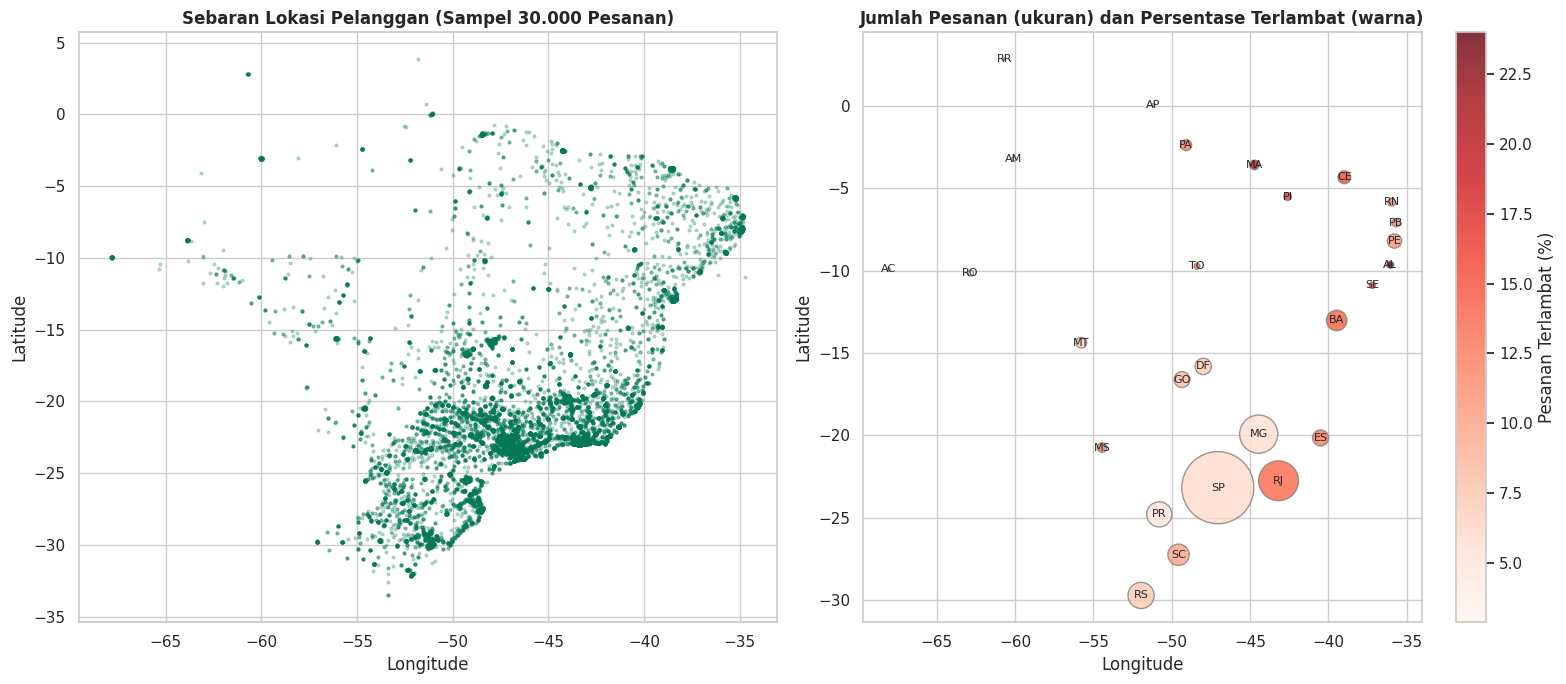

In [38]:
titik = geo_orders.dropna(subset=["lat", "lng"])
titik = titik[(titik["lat"].between(-34, 6)) & (titik["lng"].between(-74, -34))]
titik = titik.sample(30000, random_state=42)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 7))

ax[0].scatter(titik["lng"], titik["lat"], s=4, alpha=0.25, color="#047857")
ax[0].set_title("Sebaran Lokasi Pelanggan (Sampel 30.000 Pesanan)", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")

state_plot = state_df.dropna(subset=["lat", "lng"])
sc = ax[1].scatter(state_plot["lng"], state_plot["lat"], s=state_plot["jumlah_pesanan"] / 15,
                   c=state_plot["persen_terlambat"], cmap="Reds", alpha=0.8, edgecolor="gray")
for _, r in state_plot.iterrows():
    ax[1].text(r["lng"], r["lat"], r["customer_state"], ha="center", va="center", fontsize=8)
ax[1].set_title("Jumlah Pesanan (ukuran) dan Persentase Terlambat (warna)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")
plt.colorbar(sc, ax=ax[1], label="Pesanan Terlambat (%)")

plt.tight_layout()
plt.show()

### Negara bagian dengan pesanan terbanyak dan keterlambatan tertinggi

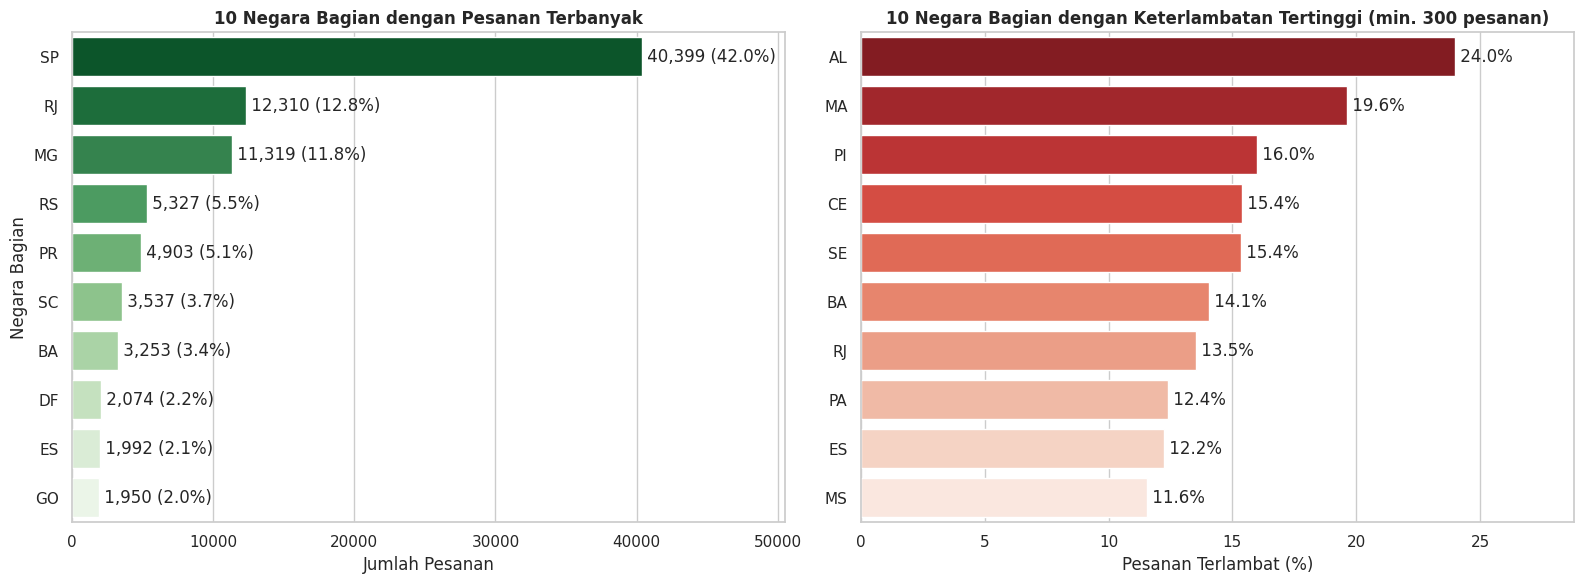

In [39]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

top_state = state_df.head(10)
sns.barplot(x="jumlah_pesanan", y="customer_state", hue="customer_state", data=top_state,
            palette="Greens_r", legend=False, ax=ax[0])
ax[0].set_title("10 Negara Bagian dengan Pesanan Terbanyak", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Jumlah Pesanan")
ax[0].set_ylabel("Negara Bagian")
for i, (n, p) in enumerate(zip(top_state["jumlah_pesanan"], top_state["persen_pesanan"])):
    ax[0].text(n, i, f" {n:,} ({p:.1f}%)", va="center")
ax[0].set_xlim(0, top_state["jumlah_pesanan"].max() * 1.25)

late_state = state_df[state_df["jumlah_pesanan"] >= 300].sort_values("persen_terlambat", ascending=False).head(10)
sns.barplot(x="persen_terlambat", y="customer_state", hue="customer_state", data=late_state,
            palette="Reds_r", legend=False, ax=ax[1])
ax[1].set_title("10 Negara Bagian dengan Keterlambatan Tertinggi (min. 300 pesanan)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Pesanan Terlambat (%)")
ax[1].set_ylabel("")
for i, v in enumerate(late_state["persen_terlambat"]):
    ax[1].text(v, i, f" {v:.1f}%", va="center")
ax[1].set_xlim(0, late_state["persen_terlambat"].max() * 1.2)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pelanggan sangat terpusat di wilayah tenggara Brasil. Negara bagian São Paulo (SP) memberikan sekitar 42% dari pesanan, diikuti oleh Rio de Janeiro (RJ) sekitar 12,8% dan Minas Gerais (MG) sekitar 11,8%. Peta tersebut menunjukkan bahwa banyak pelanggan terletak di daerah pesisir selatan dan sedikit di wilayah utara.
- Persentase keterlambatan berbeda jauh antarwilayah. Dengan minimum 300 pesanan, daerah di bagian timur laut seperti AL (sekitar 24%), MA (20%), PI (16%), CE (15%), dan SE (15%) memiliki persentase keterlambatan tertinggi, jauh melebihi rata-rata keseluruhan yaitu 8,13%.
- RJ dan BA perlu perhatian khusus. Keduanya merupakan pasar besar dengan jumlah pesanan mencapai 12.310 dan 3.253, tetapi tingkat keterlambatannya masing-masing sebesar 13,5% dan 14,1%, serta rata-rata skornya yaitu 3,97 dan 3,93 yang termasuk paling rendah di antara sepuluh negara bagian dengan pesanan terbanyak.
- Sekitar 60% penjual berada di SP. Jarak mungkin memengaruhi keterlambatan di bagian timur laut, tetapi RJ dan ES berada dekat dengan SP namun tetap mengalami keterlambatan lebih dari 12%, sehingga penyebabnya tidak bisa ditentukan hanya berdasarkan jarak saja. Penyebabnya tentu harus dicari tahu dengan data dari mitra logistik.

## Conclusion & Recommendation

**Conclusion pertanyaan 1:** Kategori produk apa saja yang memiliki jumlah pendapatan dari harga barang tanpa ongkos kirim tertinggi dan terendah pada pesanan delivered selama tahun 2017-2018, sebagai dasar penentuan prioritas stok dan anggaran promosi?

- Antara tahun 2017 dan 2018, platform mencatat total pendapatan sekitar BRL 13,18 juta dari 74 kategori produk. Kategori dengan pendapatan paling tinggi adalah health_beauty (BRL 1,23 juta, 9,3%), watches_gifts (BRL 1,16 juta, 8,8%), bed_bath_table (BRL 1,02 juta, 7,8%), sports_leisure (7,2%), dan computers_accessories (6,7%). Lima kategori ini berkontribusi 39,9% dari total pendapatan, dan hanya 18 kategori yang sudah cukup untuk mencapai 80%, sehingga pendapatan sangat terkonsentrasi pada sejumlah kecil kategori. Posisi watches_gifts di urutan kedua didukung oleh harga rata-rata yang tinggi (sekitar BRL 199), sedangkan bed_bath_table menonjol karena jumlah pesanannya yang banyak (9.267 pesanan). Kategori dengan pendapatan terendah adalah security_and_services (BRL 283 dari 2 pesanan), fashion_childrens_clothes, cds_dvds_musicals, home_comfort_2, dan flowers. Pada periode Januari sampai Agustus, delapan dari sepuluh kategori teratas tumbuh lebih dari 100% pada tahun 2018, sedangkan cool_stuff (sekitar 10%) dan garden_tools (sekitar 54%) tumbuh paling lambat.

**Conclusion pertanyaan 2:**
Bagaimana perbedaan rata-rata skor ulasan antara pesanan yang tiba tepat waktu dan yang tiba terlambat, serta pada keterlambatan berapa hari skor ulasan mulai menurun tajam, pada pesanan delivered selama tahun 2017-2018, sebagai dasar penentuan batas keterlambatan untuk peningkatan kinerja tim logistik?
- Pesanan yang terlambat berkaitan dengan skor ulasan yang jauh lebih rendah. Sebanyak 8,13% pesanan tiba setelah tanggal perkiraan. Rata-rata skor pesanan terlambat adalah 2,57, sedangkan pesanan tepat waktu 4,30, dengan selisih 1,73 poin. Ulasan negatif (skor 1 atau 2) tercatat 54,0% pada pesanan terlambat dan hanya 9,2% pada pesanan tepat waktu. Korelasi Spearman pada pesanan terlambat adalah -0,52, yang berarti semakin lama keterlambatan, semakin rendah skor yang diberikan. Penurunan skor sudah terlihat sejak keterlambatan 0-3 hari: skor turun 0,43 poin menjadi 3,77 (dari 4,20 pada kelompok lebih awal 0-7 hari), dan ulasan buruk naik hampir dua kali lipat dari 10,19% menjadi 19,09%. Penurunan paling tajam terjadi pada keterlambatan 3-7 hari (skor 2,32, ulasan buruk 61,25%), kemudian skor bertahan di kisaran 1,7 pada keterlambatan lebih dari 7 hari. Dengan demikian, hari ketiga menjadi titik kritis. Temuan ini menunjukkan adanya hubungan, tetapi belum membuktikan sebab akibat, karena skor ulasan juga dipengaruhi faktor lain seperti kualitas produk.

**Conclusion Analisis Lanjutan:**
Hasil RFM menunjukkan bahwa 97% pelanggan hanya melakukan pembelian satu kali. Segmen Lama Bernilai Tinggi (21.665 pelanggan) berkontribusi 37,2% terhadap total nilai transaksi dan menjadi peluang terbesar untuk diaktifkan kembali.
Analisis geospasial menunjukkan bahwa 42% pesanan berasal dari SP, dan keterlambatan tertinggi terjadi di wilayah timur laut (AL, MA, PI, CE, SE) serta di dua pasar utama, yaitu RJ dan BA.

**Rekomendasi Action Item:**
- Fokus pada lima kategori utama (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories) untuk pengelolaan stok dan anggaran promosi, karena kategori ini menyumbang sekitar 40% pendapatan. Untuk watches_gifts, arahkan promosi pada nilai tinggi per pesanan. Pada kategori bed_bath_table, manfaatkan jumlah pesanan besar melalui paket produk atau tawaran barang pelengkap.
- Siapkan stok lebih awal untuk kategori yang berkembang pesat (watches_gifts, health_beauty, housewares, auto), dan tinjau strategi untuk cool_stuff dan garden_tools yang pertumbuhannya melambat.
- Periksa jumlah produk dalam kategori dengan kontribusi sangat kecil (seperti security_and_services dan fashion_childrens_clothes) sebelum memutuskan untuk mempertahankan, menggabung, atau mengurangi mereka.
- Tetapkan batas keterlambatan 3 hari sebagai titik eskalasi bagi tim logistik. Pesanan yang diperkirakan akan melewati batas ini perlu mendapatkan pemberitahuan dan kompensasi (misalnya voucher) sebelum pelanggan memberikan ulasan.
- Tingkatkan estimasi tanggal kedatangan dan layanan pengiriman di AL, MA, PI, CE, SE, serta RJ dan BA, mengingat volume pesanan yang tinggi. Selain itu, evaluasi pula kinerja mitra logistik di area ini.
- Lakukan kampanye untuk mengaktifkan kembali segmen Lama Bernilai Tinggi melalui email atau voucher, dan dorong pembelian kedua dari segmen Baru Bernilai Tinggi.